# Soal 1 - Data Inspection, Cleaning and Processing

### Dependencies

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Import Data

In [2]:
df = pd.read_csv('sales_transactions_raw.csv')

df.head()

,order_id,order_date,region,channel,customer_id,customer_type,sales_rep,category,product,qty,discount,status,unit_price,revenue,cost
0,ORD-100001,2024-09-01,Jakarta,Offline,C00438,UMKM,SR02,Smartphone,Smartphone Lumo X,4,0.1,Completed,5500000.0,19800000.0,19274000.0
1,ORD-100002,2024-09-01,Jawa Timur,Offline,K0002,Korporat,SR09,Peralatan Kantor,Kursi Ergonomis E1,20,0.1,Completed,1900000.0,34200000.0,26338000.0
2,ORD-100003,2024-09-01,Jawa Barat,Online,C01918,Retail,SYS-ONLINE,Laptop,Laptop Axio Pro 15,1,0.1,Completed,13000000.0,11700000.0,11642500.0
3,ORD-100004,2024-09-01,Kalimantan,Offline,C00108,Retail,SR14,Aksesoris,Keyboard Mekanik K7,1,0.0,Completed,650000.0,650000.0,401000.0
4,ORD-100005,2024-09-01,Sulawesi,Online,C01567,Retail,SYS-ONLINE,Smartphone,Smartphone Lumo X,2,0.1,Completed,5500000.0,9900000.0,9743000.0


In [3]:
df.shape

(7309, 15)

Dimensi dataset: 7309 baris data dengan 15 kolom

### Inspeksi Data

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7309 entries, 0 to 7308
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   order_id       7309 non-null   str    
 1   order_date     7309 non-null   str    
 2   region         7175 non-null   str    
 3   channel        7309 non-null   str    
 4   customer_id    7309 non-null   str    
 5   customer_type  7309 non-null   str    
 6   sales_rep      7309 non-null   str    
 7   category       7309 non-null   str    
 8   product        7309 non-null   str    
 9   qty            7309 non-null   int64  
 10  discount       7309 non-null   float64
 11  status         7309 non-null   str    
 12  unit_price     7309 non-null   float64
 13  revenue        7309 non-null   float64
 14  cost           6789 non-null   float64
dtypes: float64(4), int64(1), str(10)
memory usage: 856.7 KB


Notes:
- *order_date* bertipe string
- nilai null pada *region* dan *cost*

In [5]:
df['order_date'].sample(15)

324     2024-12-09
6005    2026-02-06
3849    2025-10-18
2659    2025-06-14
955     2024-12-14
2201    2025-04-27
3236    2025-12-08
5079    2026-02-28
6207    2026-06-24
4335    2025-07-12
6373    05/07/2026
1076    2024-12-24
3020    2025-07-24
1779    2025-03-15
3820    2025-10-14
Name: order_date, dtype: str

In [6]:
date1 = df[df['order_date'].str.contains('/')]

date1.sample(10)

,order_id,order_date,region,channel,customer_id,customer_type,sales_rep,category,product,qty,discount,status,unit_price,revenue,cost
5824,ORD-105731,11/05/2026,Jakarta,Offline,C02289,Retail,SR01,Smartphone,Smartphone Lumo X,1,0.05,Completed,5500.0,5225.0,4747.6
6100,ORD-105983,11/06/2026,Jawa Timur,Offline,C00786,UMKM,SR07,Networking,Switch 8 Port S8,14,20.00,Completed,450.0,5040.0,NaN
6077,ORD-106956,07/06/2026,Sumatera,Offline,C01424,Retail,SR10,laptop,Laptop Veno 13,1,0.00,Completed,6200.0,6200.0,5524.4
6221,ORD-106110,25/06/2026,Sulawesi,Offline,C01564,UMKM,SR17,Laptop,Laptop Axio Pro 15,2,0.05,Completed,13000.0,24700.0,23477.4
5784,ORD-105684,07/05/2026,Jakarta,Offline,K0003,Korporat,SR03,Printer & Tinta,Tinta Botol Set CMYK,10,0.05,Completed,280.0,2660.0,1664.0
7068,ORD-106857,05/09/2026,Kalimantan,Offline,C00288,UMKM,SR13,Printer&Tinta,Printer InkJet P200,4,0.00,Completed,2100.0,8400.0,6743.6
6536,RET-106323,21/07/2026,Jawa Barat,Offline,C00693,Retail,SR05,Smartphone,Smartphone Lumo X,-1,0.00,Returned,5500.0,-5500.0,-4851.2
6225,ORD-106114,25/06/2026,Sulawesi,Offline,C01107,Retail,SR16,Peralatan Kantor,Kertas A4 80gsm (rim),5,0.00,Completed,55.0,275.0,192.0
6870,ORD-106692,19/08/2026,Jakarta,Offline,C00442,Retail,SR02,Printer & Tinta,Printer InkJet P200,2,0.05,Completed,2100.0,3990.0,3398.8
6760,ORD-106575,08/08/2026,Sumatra,Offline,C00965,Retail,SR11,Laptop,Laptop Axio 14,2,0.00,Completed,8500.0,17000.0,15355.0


Notes: format order_date tidak konsisten. YYYY-MM-DD dan DD/MM/YYYY

In [7]:
df['region'].unique()

<StringArray>
[    'Jakarta',  'Jawa Timur',  'Jawa Barat',  'Kalimantan',    'Sulawesi',
    'Sumatera',        'JKT ',           nan,  'kalimantan',       'Jatim',
     'jakarta', 'Jawa barat ',    'SULAWESI',       'Jabar', 'DKI Jakarta',
     'Sumatra',  'jawa timur']
Length: 17, dtype: str

In [8]:
df['channel'].unique()

<StringArray>
['Offline', 'Online', 'ONLINE', 'online', 'E-Commerce']
Length: 5, dtype: str

In [9]:
df['customer_type'].unique()

<StringArray>
['UMKM', 'Korporat', 'Retail']
Length: 3, dtype: str

In [10]:
df['category'].unique()

<StringArray>
[      'Smartphone', 'Peralatan Kantor',           'Laptop',
        'Aksesoris',       'Networking',  'Printer & Tinta',
           'LAPTOP',       'networking',       'aksesoris ',
    'Printer&Tinta', 'Peralatan kantor',               'HP',
         'Aksesori',              'ATK',           'laptop',
       'smartphone']
Length: 16, dtype: str

In [11]:
df['status'].unique()

<StringArray>
['Completed', 'Cancelled', 'Returned']
Length: 3, dtype: str

Notes: format inkonsisten pada kolom *region*, *channel*, dan *category*

In [12]:
df_cust = df[~df['order_id'].str.startswith('ORD-10')]

df_cust.sample(15)

,order_id,order_date,region,channel,customer_id,customer_type,sales_rep,category,product,qty,discount,status,unit_price,revenue,cost
5510,ORD-T029,04/04/2026,Jakarta,Offline,TEST,Retail,dummy,Aksesoris,Headset USB H3,1,0.00,Completed,1.0,0.0,0.0
150,RET-100014,2024-09-05,Jawa Barat,Offline,C01329,UMKM,SR05,Peralatan Kantor,Kursi Ergonomis E1,-6,0.00,Returned,1900000.0,-11400000.0,-7766400.0
5380,ORD-T009,2026-03-28,Jakarta,Offline,TEST,Retail,dummy,Networking,Switch 8 Port S8,1,0.00,Completed,1.0,0.0,0.0
3823,RET-103538,2025-10-14,Sulawesi,Online,C01521,Retail,SYS-ONLINE,Aksesoris,Keyboard Mekanik K7,-5,0.00,Returned,650000.0,-3250000.0,-1976000.0
1460,RET-102913,2025-08-02,Jawa Barat,Offline,K0129,Korporat,SR06,Networking,Switch 8 Port S8,-35,0.00,Returned,450000.0,-15750000.0,NaN
6590,RET-106351,26/07/2026,Sumatera,Offline,C00533,Retail,SR10,Peralatan Kantor,Kertas A4 80gsm (rim),-3,0.00,Returned,55.0,-165.0,-115.8
3731,RET-101557,2025-03-10,NaN,Online,K0034,Korporat,SYS-ONLINE,Printer & Tinta,Tinta Botol Set CMYK,-6,0.10,Returned,280000.0,-1512000.0,-997200.0
4716,RET-104470,2026-01-13,Sulawesi,Offline,C01680,Retail,SR18,Peralatan Kantor,Kursi Ergonomis E1,-2,0.10,Returned,1900000.0,-3420000.0,-2575800.0
6602,RET-106348,2026-07-27,Jakarta,Online,C00217,Retail,SYS-ONLINE,Peralatan Kantor,Kursi Ergonomis E1,-1,0.10,Returned,1900000.0,-1710000.0,-1299200.0
5429,ORD-T017,2026-03-31,Jakarta,Offline,TEST,Retail,dummy,Smartphone,Smartphone Lumo A5,1,0.00,Completed,0.0,0.0,0.0


Notes:
- ORD-10xxx untuk order completed
- RET-10xxx untuk order returned
- ORD-T0xx untuk test order (dummy)

In [13]:
df_dummy = df[df['order_id'].str.startswith('ORD-T0')]

print(df_dummy.shape[0])

32


Notes: Terdapat 32 baris data test order

In [14]:
df.duplicated().sum()

np.int64(150)

In [15]:
df_duplicate = df[df.order_id.duplicated(keep=False)].sort_values("order_id")

df_duplicate.head(10)

,order_id,order_date,region,channel,customer_id,customer_type,sales_rep,category,product,qty,discount,status,unit_price,revenue,cost
4,ORD-100005,2024-09-01,Sulawesi,Online,C01567,Retail,SYS-ONLINE,Smartphone,Smartphone Lumo X,2,0.10,Completed,5500000.0,9900000.0,9743000.0
5,ORD-100005,2024-09-01,Sulawesi,Online,C01567,Retail,SYS-ONLINE,Smartphone,Smartphone Lumo X,2,0.10,Completed,5500000.0,9900000.0,9743000.0
42,ORD-100017,2024-09-02,Jakarta,Offline,C00364,Retail,SR02,Peralatan Kantor,Kursi Ergonomis E1,3,0.05,Completed,1900000.0,5415000.0,3905700.0
43,ORD-100017,2024-09-02,Jakarta,Offline,C00364,Retail,SR02,Peralatan Kantor,Kursi Ergonomis E1,3,0.05,Completed,1900000.0,5415000.0,3905700.0
350,ORD-100107,2024-09-14,Jakarta,Offline,C01541,UMKM,SR01,Smartphone,Smartphone Lumo X,3,0.00,Completed,5500000.0,16500000.0,14237700.0
349,ORD-100107,2024-09-14,Jakarta,Offline,C01541,UMKM,SR01,Smartphone,Smartphone Lumo X,3,0.00,Completed,5500000.0,16500000.0,14237700.0
351,ORD-100108,2024-09-14,jakarta,Offline,C01700,UMKM,SR01,Smartphone,Smartphone Lumo A5,4,0.00,Completed,2800000.0,11200000.0,9734800.0
352,ORD-100108,2024-09-14,jakarta,Offline,C01700,UMKM,SR01,Smartphone,Smartphone Lumo A5,4,0.00,Completed,2800000.0,11200000.0,9734800.0
380,ORD-100134,2024-09-17,Jakarta,Online,C02231,Retail,SYS-ONLINE,Aksesoris,Keyboard Mekanik K7,2,0.05,Completed,650000.0,1235000.0,789600.0
379,ORD-100134,2024-09-17,Jakarta,Online,C02231,Retail,SYS-ONLINE,Aksesoris,Keyboard Mekanik K7,2,0.05,Completed,650000.0,1235000.0,789600.0


In [16]:
df_duplicate.shape[0]

300

In [17]:
df_duplicate['order_id'].nunique()

150

In [18]:
df_duplicate['order_id'].value_counts()

order_id
ORD-100005    2
ORD-100017    2
ORD-100107    2
ORD-100108    2
ORD-100134    2
             ..
ORD-106917    2
ORD-106921    2
ORD-106932    2
RET-100162    2
RET-101729    2
Name: count, Length: 150, dtype: int64

Notes: Ada 300 row data duplikat dengan frekuensi kemunculan 2 kali (150 row yang terduplikat)

In [19]:
num_cols = ["qty", "discount", "unit_price", "revenue", "cost"]

df[num_cols].describe()

,qty,discount,unit_price,revenue,cost
count,7309.000000,7309.000000,7.309000e+03,7.309000e+03,6.789000e+03
mean,5.385278,0.428825,2.474544e+06,7.443051e+06,6.726647e+06
std,14.765838,2.339969,3.464762e+06,2.680444e+07,2.497317e+07
min,-219.000000,0.000000,0.000000e+00,-4.950000e+07,-4.341420e+07
25%,1.000000,0.000000,1.800000e+05,3.600000e+05,2.114000e+05
50%,3.000000,0.050000,6.500000e+05,2.380000e+06,1.711200e+06
75%,5.000000,0.100000,2.800000e+06,8.400000e+06,7.569100e+06
max,400.000000,30.000000,1.300000e+07,1.700000e+09,1.517220e+09


In [20]:
invalid_discount = df[
    (df['discount'] < 0) | (df['discount'] > 1)
]

print(f"Invalid rows: {len(invalid_discount)}")

Invalid rows: 295


In [21]:
print(invalid_discount['discount'].value_counts().sort_index())

discount
5.0     183
10.0     63
20.0     18
25.0     17
30.0     14
Name: count, dtype: int64


In [22]:
display(invalid_discount[
    ['qty', 'discount', 'unit_price', 'revenue', 'cost']
])

,qty,discount,unit_price,revenue,cost
71,1,10.0,180000.0,162000.0,103900.0
86,1,5.0,13000000.0,12350000.0,11666400.0
101,1,5.0,8500000.0,8075000.0,7512800.0
104,2,5.0,2100000.0,3990000.0,3391800.0
111,1,5.0,6200000.0,5890000.0,5489100.0
...,...,...,...,...,...
7165,2,20.0,350000.0,560000.0,415000.0
7166,2,5.0,8500000.0,16150000.0,15413400.0
7230,6,5.0,55000.0,313500.0,225600.0
7261,5,5.0,6200000.0,29450000.0,28158500.0


Notes:
- terdapat nilai *discount* di luar rentang 0-1 (5, 10, 20, 25, 30), kemungkinan ditulis dalam skala persen
- perlu dibuktikan lewat revenue: apakah revenue dihitung dengan diskon 5% atau 500%?

In [23]:
disc_fix = np.where(df['discount'] > 1, df['discount'] / 100, df['discount'])
rev_check = df['qty'] * df['unit_price'] * (1 - disc_fix)

mismatch = df[(df['revenue'] - rev_check).abs() > 1]

print(f"Baris revenue tidak cocok: {len(mismatch)}")
mismatch[['order_id', 'qty', 'unit_price', 'discount', 'revenue']]

Baris revenue tidak cocok: 9


,order_id,qty,unit_price,discount,revenue
5361,ORD-T004,2,1.0,0.0,0.0
5400,ORD-T012,2,1.0,0.0,0.0
5415,ORD-T015,2,1.0,0.0,0.0
5430,ORD-T018,2,1.0,0.0,0.0
5483,ORD-T023,2,1.0,0.0,0.0
5499,ORD-T026,2,1.0,0.0,0.0
5500,ORD-T027,2,1.0,0.0,0.0
5509,ORD-T028,2,1.0,0.0,0.0
5511,ORD-T030,2,1.0,0.0,0.0


Notes:
- jika *discount* > 1 dibaca sebagai persen (dibagi 100), revenue cocok di semua baris, kecuali 9 baris test order (ORD-T)
- artinya *discount* memang tercampur dua skala, solusinya dibagi 100 untuk nilai > 1

In [24]:
df_nt = df[~df['order_id'].str.startswith('ORD-T')]   # tanpa test order

price_ref = df_nt.groupby('product')['unit_price'].agg(lambda s: s.mode()[0])
price_ratio = (df_nt['unit_price'] / df_nt['product'].map(price_ref)).round(4)

price_ratio.value_counts()

1.000    6271
0.001    1006
Name: count, dtype: int64

In [25]:
scaled = df_nt[price_ratio == 0.001]

print(f"Jumlah baris: {len(scaled)}")
print(f"Order pertama: {scaled['order_id'].min()} | terakhir: {scaled['order_id'].max()}")
scaled[['order_id', 'order_date', 'product', 'qty', 'unit_price', 'revenue', 'cost']].head()

Jumlah baris: 1006
Order pertama: ORD-105407 | terakhir: RET-106721


,order_id,order_date,product,qty,unit_price,revenue,cost
5445,ORD-105407,01/04/2026,Laptop Veno 13,2,6200.0,12400.0,11031.0
5446,ORD-105409,01/04/2026,Laptop Veno 13,9,6200.0,53010.0,49329.0
5447,ORD-105410,01/04/2026,Smartphone Lumo A5,4,2800.0,8960.0,9803.2
5448,ORD-105412,01/04/2026,Mouse Wireless M20,4,180.0,720.0,413.6
5449,ORD-105414,01/04/2026,Kertas A4 80gsm (rim),4,55.0,220.0,151.2


Notes:
- tiap produk seharusnya punya 1 harga list, tapi ada 1006 baris dengan *unit_price* tepat 1/1000 dari harga normal
- *revenue* dan *cost* di baris yang sama juga ikut kecil (contoh: Laptop Axio 14 dijual 8.500, bukan 8.500.000)
- kemungkinan data diexport dalam satuan ribuan rupiah. Muncul mulai April 2026 (ORD-105407 ke atas)
- bukan semua baris setelah April kena, jadi tidak bisa difix pakai cut-off tanggal. Harus dideteksi per baris

In [26]:
df_nt['category'].str.strip().str.lower().value_counts().head(3)

category
aksesoris     1787
laptop        1320
smartphone    1227
Name: count, dtype: int64

In [27]:
cost_null = df_nt[df_nt['cost'].isna()]

print(f"Cost null: {len(cost_null)} ({len(cost_null) / len(df_nt) * 100:.1f}%)")
cost_null['product'].value_counts().head(5)

Cost null: 520 (7.1%)


product
Switch 8 Port S8       241
Router WiFi 6 R600     228
Printer InkJet P200      7
Smartphone Lumo X        5
Keyboard Mekanik K7      5
Name: count, dtype: int64

In [28]:
cost_ratio = df_nt['cost'] / (df_nt['qty'] * df_nt['unit_price'])

cost_ratio.groupby(df_nt['product']).agg(['median', 'min', 'max']).sort_values('median')

,median,min,max
product,,,
Mouse Wireless M20,0.582778,0.574444,0.592222
Tinta Botol Set CMYK,0.588929,0.580357,0.598214
Headset USB H3,0.600286,0.591143,0.608857
Keyboard Mekanik K7,0.615692,0.606308,0.624615
Power Bank 20000mAh,0.624688,0.615625,0.634375
Switch 8 Port S8,0.665889,0.656667,0.676667
Kursi Ergonomis E1,0.683947,0.673947,0.694316
Kertas A4 80gsm (rim),0.692727,0.680000,0.701818
Router WiFi 6 R600,0.709250,0.697750,0.718833


Notes:
- cost null ada 520 baris (7.1%), dan 90% di antaranya produk Networking (Router & Switch). Jadi bukan random, kemungkinan COGS Networking tidak masuk ke sistem
- cost tidak boleh diisi 0 (margin jadi 100%), dan baris tidak boleh didrop begitu saja karena Networking jadi hilang dari analisis margin
- *cost / (qty x unit_price)* sangat stabil per produk (selisih min-max sekitar 3%), jadi cost bisa diestimasi dari rasio median produknya
- hasil imputasi hanya estimasi, jadi perlu diberi flag

In [29]:
pd.crosstab(df['status'], df['qty'] < 0)

qty,False,True
status,,
Cancelled,217,0
Completed,6957,0
Returned,0,135


In [30]:
df.groupby('status')['revenue'].agg(['min', 'max', 'sum'])

,min,max,sum
status,,,
Cancelled,165.0,9.360000e+07,1.572729e+09
Completed,0.0,1.700000e+09,5.384949e+10
Returned,-49500000.0,-1.650000e+02,-1.020955e+09


In [31]:
ret = df[df['status'] == 'Returned'].drop_duplicates()
ori = df[df['status'] != 'Returned'].drop_duplicates()

link = ret.assign(key=ret['order_id'].str[4:]).merge(
    ori.assign(key=ori['order_id'].str[4:]), on='key', suffixes=('_ret', '_ori')
)

print(f"Jumlah return: {len(ret)} | ketemu order asli: {len(link)}")
print(f"Customer sama: {(link['customer_id_ret'] == link['customer_id_ori']).mean():.1%}")
print(f"Qty berlawanan: {(link['qty_ret'] == -link['qty_ori']).mean():.1%}")
print(f"Revenue berlawanan: {(link['revenue_ret'] == -link['revenue_ori']).mean():.1%}")
print(f"Status order asli: {link['status_ori'].unique()}")

Jumlah return: 133 | ketemu order asli: 133
Customer sama: 100.0%
Qty berlawanan: 100.0%
Revenue berlawanan: 98.5%
Status order asli: <StringArray>
['Completed']
Length: 1, dtype: str


Notes:
- *Returned* dicatat sebagai baris terpisah (RET-xxxxxx) dengan qty, revenue, dan cost **negatif**, sementara order aslinya tetap *Completed*
- artinya return sudah otomatis mengurangi revenue kalau semua baris dijumlahkan. Kalau hanya filter *Completed*, revenue jadi lebih besar dari seharusnya
- *Cancelled* revenue-nya positif padahal order tidak terjadi, jadi harus dikeluarkan dari net revenue

In [32]:
df_nt.groupby('customer_type')['qty'].describe()

,count,mean,std,min,25%,50%,75%,max
customer_type,,,,,,,,
Korporat,844.0,20.292654,35.599871,-219.0,5.0,9.0,28.0,289.0
Retail,4066.0,2.496557,8.042636,-5.0,1.0,2.0,3.0,400.0
UMKM,2367.0,5.084495,4.103948,-14.0,2.0,4.0,8.0,14.0


In [33]:
df_nt[df_nt['customer_type'] == 'Retail'].nlargest(10, 'qty')[
    ['order_id', 'order_date', 'product', 'qty', 'unit_price', 'revenue']
]

,order_id,order_date,product,qty,unit_price,revenue
5678,ORD-105606,25/04/2026,Switch 8 Port S8,400,450.0,1.800000e+05
645,ORD-100441,2024-10-27,Laptop Axio 14,200,8500000.0,1.700000e+09
2052,ORD-102980,2025-08-04,Smartphone Lumo X,100,5500000.0,4.950000e+08
3302,ORD-103130,2025-08-21,Tinta Botol Set CMYK,100,280000.0,2.800000e+07
4825,ORD-104667,2026-01-28,Smartphone Lumo X,100,5500000.0,4.950000e+08
6229,ORD-106118,2026-06-25,Smartphone Lumo X,100,5500000.0,4.675000e+08
6359,ORD-106218,04/07/2026,Switch 8 Port S8,100,450.0,4.050000e+04
6988,ORD-106804,31/08/2026,Laptop Veno 13,100,6200.0,6.200000e+05
16,ORD-100483,2024-11-01,Switch 8 Port S8,5,450000.0,2.250000e+06
19,ORD-100486,2024-11-01,Router WiFi 6 R600,5,1200000.0,6.000000e+06


Notes:
- Korporat memang wajar beli banyak (median 10, max 289), tapi Retail umumnya hanya 1-5 unit
- ada 8 baris Retail dengan qty 100-400, termasuk 200 laptop (Rp1,7 miliar, baris terbesar di data). Kemungkinan salah input, tapi tidak bisa dibuktikan dari data

In [34]:
cust_c = df_nt[df_nt['customer_id'].str.startswith('C')].groupby('customer_id')['customer_type'].nunique()
cust_k = df_nt[df_nt['customer_id'].str.startswith('K')].groupby('customer_id')['customer_type'].nunique()

print(f"Customer C: {len(cust_c)} id, {(cust_c > 1).sum()} id muncul sebagai Retail DAN UMKM")
print(f"Customer K: {len(cust_k)} id, {(cust_k > 1).sum()} id punya lebih dari 1 tipe")

Customer C: 2212 id, 1170 id muncul sebagai Retail DAN UMKM
Customer K: 179 id, 0 id punya lebih dari 1 tipe


In [35]:
pd.crosstab(df_nt['channel'].str.lower().replace({'e-commerce': 'online'}), df_nt['sales_rep'] == 'SYS-ONLINE')

sales_rep,False,True
channel,,
offline,4591,0
online,0,2686


Notes:
- id customer **C** tidak unik: 53% id muncul sebagai Retail sekaligus UMKM. Jadi ranking customer Retail/UMKM hanya indikatif. Id **K** (Korporat) konsisten
- channel dan sales_rep sudah konsisten (Online = SYS-ONLINE), jadi standarisasi channel aman
- ID test order juga punya *customer_id* = TEST dan *sales_rep* = dummy

### Ringkasan Inspeksi

Data **tidak bisa langsung dipakai**. Masalah yang ditemukan:

| No | Masalah | Baris |
|---|---|---|
| 1 | Satuan ribuan rupiah di *unit_price*, *revenue*, *cost* (mulai Apr 2026) | 1006 |
| 2 | Duplikat persis | 150 |
| 3 | Test order | 32 |
| 4 | Order *Cancelled* masih punya revenue | 217 |
| 5 | *cost* null (mayoritas Networking) | 520 |
| 6 | *discount* campur skala (0.05 vs 5.0) | 295 |
| 7 | Dua format tanggal | 1020 |
| 8 | Label *region*, *channel*, *category* tidak konsisten | +/- 800 |
| 9 | *region* kosong | 134 |
| 10 | Qty Retail tidak wajar (100-400) | 8 |
| 11 | *customer_id* C tidak unik | 1170 id |

### Data Cleaning

Urutan: hapus test & duplikat dulu, lalu standarisasi, lalu perbaiki satuan.

In [36]:
df_clean = df.copy()
log = [('Data awal', len(df_clean))]

#### 1. Hapus test order

In [37]:
df_clean = df_clean[~df_clean['order_id'].str.startswith('ORD-T')]
log.append(('Hapus test order', len(df_clean)))

len(df_clean)

7277

Notes: 32 baris dihapus. Tiga indikator (order_id, customer_id, sales_rep) menunjuk ke baris yang sama, dan harganya 0/1 rupiah

#### 2. Hapus duplikat

In [38]:
df_clean = df_clean.drop_duplicates(keep='first')
log.append(('Hapus duplikat persis', len(df_clean)))

assert df_clean['order_id'].is_unique
len(df_clean)

7127

Notes: 150 baris dihapus. Semua pasangan duplikat identik di 15 kolom, jadi ini double load, bukan order kedua

#### 3. Standarisasi region, channel, category

In [39]:
map_region = {
    'jakarta': 'Jakarta', 'dki jakarta': 'Jakarta', 'jkt': 'Jakarta',
    'jawa barat': 'Jawa Barat', 'jabar': 'Jawa Barat',
    'jawa timur': 'Jawa Timur', 'jatim': 'Jawa Timur',
    'sumatera': 'Sumatera', 'sumatra': 'Sumatera',
    'kalimantan': 'Kalimantan', 'sulawesi': 'Sulawesi', '': 'Unknown'
}
map_channel = {'online': 'Online', 'e-commerce': 'Online', 'offline': 'Offline'}
map_category = {
    'aksesoris': 'Aksesoris', 'aksesori': 'Aksesoris',
    'laptop': 'Laptop', 'hp': 'Smartphone', 'smartphone': 'Smartphone',
    'networking': 'Networking',
    'printer & tinta': 'Printer & Tinta', 'printer&tinta': 'Printer & Tinta',
    'peralatan kantor': 'Peralatan Kantor', 'atk': 'Peralatan Kantor'
}

def standardize(series, mapping):
    key = series.fillna('').str.strip().str.lower()
    out = key.map(mapping)
    assert out.notna().all(), key[out.isna()].unique()   # pastikan tidak ada label yang terlewat
    return out

df_clean['region'] = standardize(df_clean['region'], map_region)
df_clean['channel'] = standardize(df_clean['channel'], map_channel)
df_clean['category'] = standardize(df_clean['category'], map_category)

print(df_clean['region'].value_counts(), '\n')
print(df_clean['channel'].value_counts(), '\n')
print(df_clean['category'].value_counts())

region
Jakarta       1945
Jawa Barat    1389
Jawa Timur    1308
Sumatera      1006
Kalimantan     712
Sulawesi       636
Unknown        131
Name: count, dtype: int64 

channel
Offline    4515
Online     2612
Name: count, dtype: int64 

category
Aksesoris           1806
Laptop              1293
Smartphone          1226
Peralatan Kantor    1138
Printer & Tinta      905
Networking           759
Name: count, dtype: int64


In [40]:
# validasi: setelah dimapping, 1 produk harus masuk tepat 1 kategori
df_clean.groupby('product')['category'].nunique().max()

np.int64(1)

Notes:
- mapping HP -> Smartphone dan ATK -> Peralatan Kantor divalidasi lewat produk: tiap produk hanya masuk 1 kategori (nilai 1 di atas)
- *region* kosong diisi **Unknown** dan barisnya tetap dipakai. Tidak diisi dari customer karena *customer_id* tidak bisa dipercaya

#### 4. Format tanggal

In [41]:
is_slash = df_clean['order_date'].str.contains('/')

d_iso = pd.to_datetime(df_clean.loc[~is_slash, 'order_date'], format='%Y-%m-%d')
d_slash = pd.to_datetime(df_clean.loc[is_slash, 'order_date'], format='%d/%m/%Y')

df_clean['order_date'] = pd.concat([d_iso, d_slash]).sort_index()

print(df_clean['order_date'].min(), '->', df_clean['order_date'].max())
df_clean['order_date'].dt.strftime('%Y-%m').value_counts().sort_index().tail(4)

2024-09-01 00:00:00 -> 2026-09-15 00:00:00


order_date
2026-06    288
2026-07    358
2026-08    302
2026-09    154
Name: count, dtype: int64

Notes:
- format DD/MM/YYYY dipastikan day-first: bagian pertama > 12 di 530 baris, bagian kedua tidak pernah > 12
- data berakhir **15 Sep 2026**, jadi bulan Sep 2026 **belum penuh** (154 baris setelah cleaning vs +/- 300 normal). Jangan dibaca sebagai penurunan

#### 5. Discount ke skala 0-1

In [42]:
df_clean['discount_was_pct'] = df_clean['discount'] > 1
df_clean['discount'] = np.where(df_clean['discount'] > 1, df_clean['discount'] / 100, df_clean['discount'])

print(f"Baris diperbaiki: {df_clean['discount_was_pct'].sum()}")
df_clean['discount'].value_counts().sort_index()

Baris diperbaiki: 293


discount
0.00    3153
0.05    1998
0.08       9
0.10    1130
0.12       8
0.15     196
0.20     207
0.25     220
0.30     206
Name: count, dtype: int64

#### 6. Satuan ribuan menjadi rupiah

In [43]:
price_ref = df_clean.groupby('product')['unit_price'].agg(lambda s: s.mode()[0])
ratio = (df_clean['unit_price'] / df_clean['product'].map(price_ref)).round(4)

assert ratio.isin([1.0, 0.001]).all()   # hanya ada 2 kemungkinan: normal atau 1/1000

df_clean['price_scale_fixed'] = ratio == 0.001

for col in ['unit_price', 'revenue', 'cost']:
    df_clean[col] = np.where(df_clean['price_scale_fixed'], df_clean[col] * 1000, df_clean[col])

print(f"Baris diperbaiki: {df_clean['price_scale_fixed'].sum()}")

Baris diperbaiki: 982


In [44]:
# cek ulang: revenue harus = qty x unit_price x (1 - discount) di semua baris
gap = (df_clean['revenue'] - df_clean['qty'] * df_clean['unit_price'] * (1 - df_clean['discount'])).abs()

print(f"Selisih terbesar: {gap.max():.2f} rupiah | baris selisih > 1 rupiah: {(gap > 1).sum()}")

Selisih terbesar: 0.00 rupiah | baris selisih > 1 rupiah: 0


Notes:
- satuan dideteksi dari rasio ke harga normal produk (bukan dari tanggal), karena hanya sebagian baris setelah April yang kena
- bukti benar: setelah dikali 1000, revenue cocok dengan qty x harga x (1 - diskon) di seluruh baris (selisih 0)

#### 7. Imputasi cost

In [45]:
df_clean['cost_imputed'] = df_clean['cost'].isna()

cost_ratio = df_clean['cost'] / (df_clean['qty'] * df_clean['unit_price'])
ratio_median = cost_ratio.groupby(df_clean['product']).median()

cost_est = (df_clean['product'].map(ratio_median) * df_clean['qty'] * df_clean['unit_price']).round(0)
df_clean['cost'] = df_clean['cost'].fillna(cost_est)

print(f"Cost diimputasi: {df_clean['cost_imputed'].sum()} baris")
df_clean.groupby('category')['cost_imputed'].mean().mul(100).round(1)

Cost diimputasi: 506 baris


category
Aksesoris            0.8
Laptop               0.6
Networking          59.9
Peralatan Kantor     0.7
Printer & Tinta      1.2
Smartphone           0.7
Name: cost_imputed, dtype: float64

Notes:
- cost diisi dari rasio median per produk x qty x unit_price, dan diberi flag *cost_imputed*
- sekitar 60% baris Networking memakai cost estimasi, jadi margin Networking = **estimasi**. Perlu konfirmasi COGS asli dari finance

#### 8. Flag qty outlier Retail

In [46]:
retail_normal = df_clean[(df_clean['customer_type'] == 'Retail') & (df_clean['qty'].abs() <= 20)]
print(f"Qty Retail terbesar yang wajar: {retail_normal['qty'].abs().max()}")

df_clean['qty_outlier'] = (df_clean['customer_type'] == 'Retail') & (df_clean['qty'].abs() > 20)

df_clean[df_clean['qty_outlier']][['order_id', 'order_date', 'product', 'qty', 'revenue']]

Qty Retail terbesar yang wajar: 5


,order_id,order_date,product,qty,revenue
645,ORD-100441,2024-10-27,Laptop Axio 14,200,1.700000e+09
2052,ORD-102980,2025-08-04,Smartphone Lumo X,100,4.950000e+08
3302,ORD-103130,2025-08-21,Tinta Botol Set CMYK,100,2.800000e+07
4825,ORD-104667,2026-01-28,Smartphone Lumo X,100,4.950000e+08
5678,ORD-105606,2026-04-25,Switch 8 Port S8,400,1.800000e+08
6229,ORD-106118,2026-06-25,Smartphone Lumo X,100,4.675000e+08
6359,ORD-106218,2026-07-04,Switch 8 Port S8,100,4.050000e+07
6988,ORD-106804,2026-08-31,Laptop Veno 13,100,6.200000e+08


Notes:
- 8 baris (Rp4,0 miliar) **tidak dihapus**, hanya diberi flag dan dipisah dari analisis utama karena tidak bisa diverifikasi
- dampaknya ke hasil akhir ditunjukkan di tabel sensitivitas

In [47]:
log.append(('Data bersih (semua flag)', len(df_clean)))

pd.DataFrame(log, columns=['step', 'jumlah_baris'])

,step,jumlah_baris
0,Data awal,7309
1,Hapus test order,7277
2,Hapus duplikat persis,7127
3,Data bersih (semua flag),7127


### Data Processing

#### Field analisis

Aturan:
- *Cancelled*: net revenue dan net cost = 0 (order tidak terjadi)
- *Returned*: sudah bernilai negatif, jadi cukup dijumlahkan (otomatis mengurangi)
- gross profit = net revenue - net cost. Margin % dihitung dari total (gross profit / net revenue), bukan rata-rata margin per baris

In [48]:
df_clean['year'] = df_clean['order_date'].dt.year
df_clean['month'] = df_clean['order_date'].dt.month
df_clean['quarter'] = df_clean['order_date'].dt.quarter
df_clean['year_month'] = df_clean['order_date'].dt.strftime('%Y-%m')
df_clean['year_quarter'] = df_clean['year'].astype(str) + '-Q' + df_clean['quarter'].astype(str)

aktif = df_clean['status'] != 'Cancelled'

df_clean['net_revenue'] = np.where(aktif, df_clean['revenue'], 0)
df_clean['net_cost'] = np.where(aktif, df_clean['cost'], 0)
df_clean['gross_profit'] = df_clean['net_revenue'] - df_clean['net_cost']

df_clean['is_cancelled'] = df_clean['status'] == 'Cancelled'
df_clean['is_return'] = df_clean['status'] == 'Returned'
df_clean['list_value'] = np.where(aktif, df_clean['qty'] * df_clean['unit_price'], 0)
df_clean['discount_band'] = pd.cut(df_clean['discount'], [-0.001, 0, 0.05, 0.10, 0.15, 0.20, 0.35],
                                   labels=['0%', '1-5%', '6-10%', '11-15%', '16-20%', '21-30%'])

# dataset analisis = tanpa qty outlier
df_final = df_clean[~df_clean['qty_outlier']]
df_outlier = df_clean[df_clean['qty_outlier']]

print(f"df_final: {len(df_final)} baris | df_outlier: {len(df_outlier)} baris")
df_final[['order_id', 'year_month', 'status', 'revenue', 'cost', 'net_revenue', 'gross_profit']].head()

df_final: 7119 baris | df_outlier: 8 baris


,order_id,year_month,status,revenue,cost,net_revenue,gross_profit
0,ORD-100001,2024-09,Completed,19800000.0,19274000.0,19800000.0,526000.0
1,ORD-100002,2024-09,Completed,34200000.0,26338000.0,34200000.0,7862000.0
2,ORD-100003,2024-09,Completed,11700000.0,11642500.0,11700000.0,57500.0
3,ORD-100004,2024-09,Completed,650000.0,401000.0,650000.0,249000.0
4,ORD-100005,2024-09,Completed,9900000.0,9743000.0,9900000.0,157000.0


#### Tabel 1: Net revenue, gross profit, dan margin per bulan

In [49]:
monthly = df_final.groupby('year_month').agg(
    net_revenue=('net_revenue', 'sum'),
    gross_profit=('gross_profit', 'sum'),
    jumlah_order=('is_cancelled', lambda s: (~s).sum())
)
monthly['margin_pct'] = (monthly['gross_profit'] / monthly['net_revenue'] * 100).round(2)
monthly['mom_pct'] = (monthly['net_revenue'].pct_change() * 100).round(1)
monthly['catatan'] = np.where(monthly.index == '2026-09', 'bulan belum penuh (s/d 15 Sep)', '')

monthly

,net_revenue,gross_profit,jumlah_order,margin_pct,mom_pct,catatan
year_month,,,,,,
2024-09,1.798231e+09,285068550.0,242,15.85,NaN,
2024-10,1.777732e+09,256739500.0,225,14.44,-1.1,
2024-11,2.222648e+09,349582600.0,282,15.73,25.0,
2024-12,2.558929e+09,352986400.0,341,13.79,15.1,
2025-01,1.577241e+09,236160550.0,217,14.97,-38.4,
2025-02,1.969671e+09,293955050.0,251,14.92,24.9,
2025-03,2.813316e+09,454806450.0,378,16.17,42.8,
2025-04,1.763232e+09,255900350.0,208,14.51,-37.3,
2025-05,2.034898e+09,291041350.0,269,14.30,15.4,


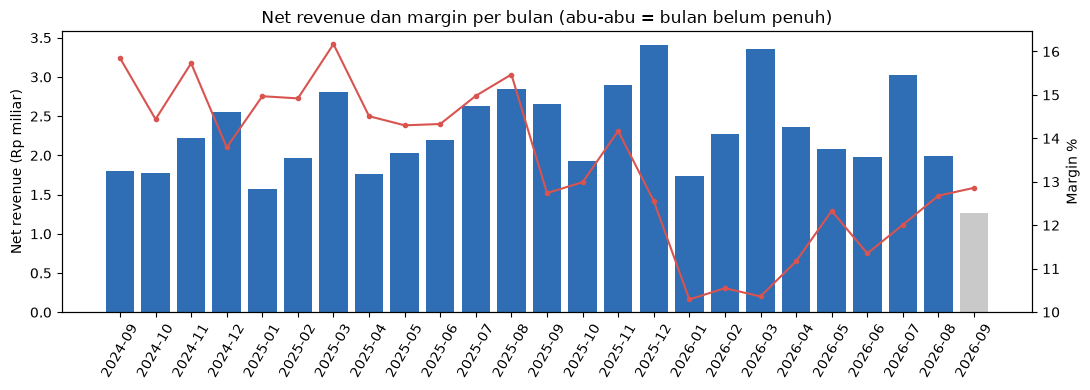

In [50]:
fig, ax = plt.subplots(figsize=(11, 4))
warna = ['#c9c9c9' if m == '2026-09' else '#2f6db5' for m in monthly.index]
ax.bar(monthly.index, monthly['net_revenue'] / 1e9, color=warna)
ax.set_ylabel('Net revenue (Rp miliar)')
ax.tick_params(axis='x', rotation=60)

ax2 = ax.twinx()
ax2.plot(monthly.index, monthly['margin_pct'], color='#d9534f', marker='o', ms=3)
ax2.set_ylabel('Margin %')

plt.title('Net revenue dan margin per bulan (abu-abu = bulan belum penuh)')
plt.tight_layout()
plt.show()

Notes:
- puncak penjualan di Maret, Juli, dan Desember; terendah di Januari
- margin turun dari sekitar 15% (2024-2025) menjadi sekitar 10-12% (2026). Penyebabnya dibahas di bagian insight

#### Tabel 2: Net revenue dan margin per region x category

In [51]:
reg_cat = df_final.groupby(['region', 'category']).agg(
    net_revenue=('net_revenue', 'sum'),
    gross_profit=('gross_profit', 'sum')
)
reg_cat['margin_pct'] = (reg_cat['gross_profit'] / reg_cat['net_revenue'] * 100).round(2)
reg_cat['share_pct'] = (reg_cat['net_revenue'] / reg_cat['net_revenue'].sum() * 100).round(2)

reg_cat = reg_cat.sort_values('net_revenue', ascending=False)
reg_cat.head(15)

,,net_revenue,gross_profit,margin_pct,share_pct
region,category,,,,
Jakarta,Laptop,6.291445e+09,378634600.0,6.02,11.01
Jawa Barat,Laptop,5.362430e+09,262644700.0,4.90,9.38
Jawa Timur,Laptop,4.282690e+09,150789600.0,3.52,7.49
Sumatera,Laptop,3.759090e+09,209247300.0,5.57,6.58
Kalimantan,Laptop,3.518090e+09,233015200.0,6.62,6.16
Jakarta,Smartphone,2.934200e+09,232601900.0,7.93,5.13
Sulawesi,Laptop,2.649795e+09,138897100.0,5.24,4.64
Jawa Barat,Smartphone,2.184085e+09,179219600.0,8.21,3.82
Jawa Timur,Smartphone,1.977240e+09,93124900.0,4.71,3.46


In [52]:
rev_pivot = (df_final.pivot_table(index='region', columns='category', values='net_revenue', aggfunc='sum', margins=True, margins_name='Total') / 1e9).round(2)
gp_pivot = df_final.pivot_table(index='region', columns='category', values='gross_profit', aggfunc='sum', margins=True, margins_name='Total')
margin_pivot = (gp_pivot / (rev_pivot * 1e9) * 100).round(1)

print('Net revenue (Rp miliar)')
print(rev_pivot, '\n')
print('Margin %')
print(margin_pivot)

Net revenue (Rp miliar)
category    Aksesoris  Laptop  Networking  Peralatan Kantor  Printer & Tinta  \
region                                                                         
Jakarta          1.29    6.29        1.20              1.97             0.67   
Jawa Barat       0.86    5.36        0.72              1.15             1.39   
Jawa Timur       1.02    4.28        0.90              1.32             0.37   
Kalimantan       0.45    3.52        0.42              0.66             0.28   
Sulawesi         0.72    2.65        0.42              0.96             0.16   
Sumatera         0.65    3.76        0.51              1.29             0.68   
Unknown          0.05    0.33        0.08              0.21             0.02   
Total            5.04   26.19        4.26              7.57             3.58   

category    Smartphone  Total  
region                         
Jakarta           2.93  14.35  
Jawa Barat        2.18  11.67  
Jawa Timur        1.98   9.87  
Kalimantan     

Notes:
- Laptop dan Smartphone mendominasi revenue di semua region, tapi margin-nya paling tipis (Laptop 3-7%, Smartphone 5-9%)
- Aksesoris dan Peralatan Kantor paling tinggi margin-nya (24-35%)
- selisih margin antar region relatif kecil dibanding selisih antar kategori

#### Tabel 3: Top 10 customer berdasarkan net revenue

In [53]:
top10 = df_final.groupby('customer_id').agg(
    customer_type=('customer_type', lambda s: s.mode()[0]),
    net_revenue=('net_revenue', 'sum'),
    gross_profit=('gross_profit', 'sum'),
    jumlah_order=('is_return', lambda s: (~s).sum())
).nlargest(10, 'net_revenue')

top10['margin_pct'] = (top10['gross_profit'] / top10['net_revenue'] * 100).round(2)
top10['share_pct'] = (top10['net_revenue'] / df_final['net_revenue'].sum() * 100).round(2)

top10

,customer_type,net_revenue,gross_profit,jumlah_order,margin_pct,share_pct
customer_id,,,,,,
K0102,Korporat,504252000.0,66033000.0,1,13.10,0.88
K0173,Korporat,481921000.0,48873600.0,7,10.14,0.84
K0127,Korporat,384269500.0,39697900.0,5,10.33,0.67
K0031,Korporat,375976000.0,76105500.0,7,20.24,0.66
K0151,Korporat,364005000.0,33982200.0,7,9.34,0.64
K0169,Korporat,358604000.0,52884100.0,5,14.75,0.63
K0011,Korporat,339939000.0,78602900.0,6,23.12,0.59
K0088,Korporat,317040800.0,49735000.0,6,15.69,0.55
K0143,Korporat,312578750.0,71671650.0,12,22.93,0.55


In [54]:
print(f"Top 10 = {top10['net_revenue'].sum() / df_final['net_revenue'].sum() * 100:.1f}% dari total net revenue")

# kalau 8 baris outlier ikut dihitung
(df_clean.groupby('customer_id')['net_revenue'].sum().nlargest(5) / 1e6).round(0)

Top 10 = 6.5% dari total net revenue


customer_id
C01919    1709.0
C01695     633.0
C02374     508.0
K0102      504.0
C01747     503.0
Name: net_revenue, dtype: float64

Notes:
- top 10 semuanya Korporat (id K) dan hanya 6.5% dari total net revenue, jadi tidak ada konsentrasi customer
- kalau 8 baris outlier ikut dihitung, ranking teratas langsung diisi customer Retail (C01919 = Rp1,7 miliar dari 1 order). Ini alasan outlier dipisah
- ranking customer C (Retail/UMKM) tetap indikatif karena id tidak unik

#### Sensitivitas: seberapa besar pengaruh tiap keputusan cleaning?

In [55]:
def kpi(rev, gp):
    return pd.Series({'net_revenue_miliar': rev.sum() / 1e9, 'gross_profit_miliar': gp.sum() / 1e9, 'margin_pct': gp.sum() / rev.sum() * 100})

# raw mentah: tanpa test order, cancelled tetap dihitung, cost null dianggap 0
raw_nt = df[~df['order_id'].str.startswith('ORD-T')]

hasil = pd.DataFrame({
    'FINAL (outlier dipisah)': kpi(df_final['net_revenue'], df_final['gross_profit']),
    'Outlier ikut dihitung': kpi(df_clean['net_revenue'], df_clean['gross_profit']),
    'Tanpa imputasi cost (drop baris)': kpi(df_final[~df_final['cost_imputed']]['net_revenue'], df_final[~df_final['cost_imputed']]['gross_profit']),
    'Tanpa fix satuan ribuan': kpi(
        np.where(df_final['price_scale_fixed'], df_final['net_revenue'] / 1000, df_final['net_revenue']),
        np.where(df_final['price_scale_fixed'], df_final['gross_profit'] / 1000, df_final['gross_profit'])
    ),
    'Data mentah apa adanya': kpi(raw_nt['revenue'], raw_nt['revenue'] - raw_nt['cost'].fillna(0)),
}).T

hasil['selisih_revenue_vs_final_pct'] = (hasil['net_revenue_miliar'] / hasil.iloc[0]['net_revenue_miliar'] - 1) * 100
hasil.round(2)

,net_revenue_miliar,gross_profit_miliar,margin_pct,selisih_revenue_vs_final_pct
FINAL (outlier dipisah),57.15,7.64,13.37,0.00
Outlier ikut dihitung,61.17,8.00,13.08,7.05
Tanpa imputasi cost (drop baris),54.53,7.00,12.84,-4.58
Tanpa fix satuan ribuan,48.74,6.42,13.17,-14.71
Data mentah apa adanya,54.40,8.73,16.05,-4.80


Notes:
- tanpa fix satuan ribuan, net revenue turun sekitar 15% dan 2026 terlihat seperti anjlok sejak April padahal tidak
- data mentah terlihat "mirip" final (selisih sekitar 5%), tapi hanya karena error saling menutupi: duplikat & cancelled menggelembungkan, sementara satuan ribuan mengecilkan. Total tampak wajar padahal rinciannya salah
- margin data mentah (16%) terlalu tinggi karena cost null dihitung 0. Margin final 13.4%
- dua keputusan yang paling perlu dikonfirmasi ke bisnis: cost Networking dan 8 baris outlier Retail

### Insight

Perhitungan di bawah memakai *df_final* (Cancelled = 0, Returned dinetting, outlier dipisah).

In [56]:
total_rev = df_final['net_revenue'].sum()
total_gp = df_final['gross_profit'].sum()
print(f"Net revenue Rp{total_rev / 1e9:.1f} miliar | Gross profit Rp{total_gp / 1e9:.1f} miliar | Margin {total_gp / total_rev * 100:.1f}%")

def ringkas(by):
    g = df_final.groupby(by, observed=True).agg(net_revenue=('net_revenue', 'sum'), gross_profit=('gross_profit', 'sum'))
    g['margin_pct'] = (g['gross_profit'] / g['net_revenue'] * 100).round(1)
    g['share_revenue_pct'] = (g['net_revenue'] / total_rev * 100).round(1)
    g['share_profit_pct'] = (g['gross_profit'] / total_gp * 100).round(1)
    return g.sort_values('net_revenue', ascending=False)

ringkas('category')

Net revenue Rp57.1 miliar | Gross profit Rp7.6 miliar | Margin 13.4%


,net_revenue,gross_profit,margin_pct,share_revenue_pct,share_profit_pct
category,,,,,
Laptop,2.619375e+10,1.392379e+09,5.3,45.8,18.2
Smartphone,1.051488e+10,8.027359e+08,7.6,18.4,10.5
Peralatan Kantor,7.566026e+09,2.060934e+09,27.2,13.2,27.0
Aksesoris,5.040795e+09,1.750488e+09,34.7,8.8,22.9
Networking,4.255238e+09,1.073153e+09,25.2,7.4,14.0
Printer & Tinta,3.576038e+09,5.629937e+08,15.7,6.3,7.4


In [57]:
ringkas('customer_type')

,net_revenue,gross_profit,margin_pct,share_revenue_pct,share_profit_pct
customer_type,,,,,
UMKM,2.003279e+10,2.445109e+09,12.2,35.1,32.0
Korporat,2.002416e+10,3.286669e+09,16.4,35.0,43.0
Retail,1.708978e+10,1.910906e+09,11.2,29.9,25.0


In [58]:
ringkas('channel')

,net_revenue,gross_profit,margin_pct,share_revenue_pct,share_profit_pct
channel,,,,,
Offline,3.667499e+10,5.570112e+09,15.2,64.2,72.9
Online,2.047174e+10,2.072571e+09,10.1,35.8,27.1


In [59]:
ringkas('discount_band')

,net_revenue,gross_profit,margin_pct,share_revenue_pct,share_profit_pct
discount_band,,,,,
0%,2.550093e+10,4.485406e+09,17.6,44.6,58.7
1-5%,1.528940e+10,2.060036e+09,13.5,26.8,27.0
6-10%,1.016089e+10,1.212382e+09,11.9,17.8,15.9
21-30%,2.529800e+09,-3.588804e+08,-14.2,4.4,-4.7
11-15%,2.479680e+09,2.592786e+08,10.5,4.3,3.4
16-20%,1.186028e+09,-1.553865e+07,-1.3,2.1,-0.2


Notes:
- Laptop + Smartphone = 64% revenue tapi hanya sekitar 29% gross profit. Aksesoris + Peralatan Kantor + Networking = 29% revenue tapi sekitar 64% gross profit
- margin turun seiring besar diskon: diskon 16-20% margin -1.3%, diskon 21-30% margin -14.2% (rugi)
- Online margin 10.1% vs Offline 15.2%

In [60]:
# perbandingan 12 bulan penuh (Sep-2026 tidak ikut karena belum penuh)
m = monthly.drop('2026-09')
y1, y2 = m.loc['2024-09':'2025-08'], m.loc['2025-09':'2026-08']

print(f"Net revenue  : {y1['net_revenue'].sum() / 1e9:.1f} -> {y2['net_revenue'].sum() / 1e9:.1f} miliar ({(y2['net_revenue'].sum() / y1['net_revenue'].sum() - 1) * 100:+.1f}%)")
print(f"Gross profit : {y1['gross_profit'].sum() / 1e9:.2f} -> {y2['gross_profit'].sum() / 1e9:.2f} miliar ({(y2['gross_profit'].sum() / y1['gross_profit'].sum() - 1) * 100:+.1f}%)")
print(f"Margin       : {y1['gross_profit'].sum() / y1['net_revenue'].sum() * 100:.1f}% -> {y2['gross_profit'].sum() / y2['net_revenue'].sum() * 100:.1f}%")

Net revenue  : 26.2 -> 29.7 miliar (+13.4%)
Gross profit : 3.93 -> 3.55 miliar (-9.4%)
Margin       : 15.0% -> 12.0%


In [61]:
# apa yang berubah? lihat diskon besar (>= 20%) per kuartal
sale = df_final[~df_final['is_cancelled'] & ~df_final['is_return']].copy()
sale['deep'] = sale['discount'] >= 0.20
sale['periode'] = np.where(sale['order_date'] < '2025-09-01', 'Sep24-Aug25', 'Sep25-Sep26')

kuartal = sale.groupby('year_quarter').apply(lambda x: pd.Series({
    'margin_pct': x['gross_profit'].sum() / x['net_revenue'].sum() * 100,
    'margin_tanpa_diskon_pct': x[x['discount'] == 0]['gross_profit'].sum() / x[x['discount'] == 0]['net_revenue'].sum() * 100,
    'baris_diskon_20plus_pct': x['deep'].mean() * 100
}), include_groups=False).round(1)

print(kuartal, '\n')
print('Margin % per channel:')
print(sale.groupby(['channel', 'periode']).apply(lambda x: x['gross_profit'].sum() / x['net_revenue'].sum() * 100, include_groups=False).unstack().round(1))

              margin_pct  margin_tanpa_diskon_pct  baris_diskon_20plus_pct
year_quarter                                                              
2024-Q3             15.7                     20.3                      0.0
2024-Q4             14.7                     16.0                      0.0
2025-Q1             15.5                     17.6                      0.0
2025-Q2             14.5                     17.2                      0.0
2025-Q3             14.5                     18.4                      4.9
2025-Q4             13.1                     17.8                     16.3
2026-Q1             10.5                     17.5                     17.4
2026-Q2             11.6                     17.5                     16.9
2026-Q3             12.3                     18.1                     15.6 

Margin % per channel:
periode  Sep24-Aug25  Sep25-Sep26
channel                          
Offline         15.8         14.7
Online          13.9          6.5


In [62]:
deep = sale[sale['deep']]

print(f"Baris diskon >= 20%: {len(deep)} (sebelum Sep 2025: {(deep['periode'] == 'Sep24-Aug25').sum()})")
print(f"Net revenue Rp{deep['net_revenue'].sum() / 1e9:.2f} miliar | gross profit Rp{deep['gross_profit'].sum() / 1e6:,.0f} juta | margin {deep['gross_profit'].sum() / deep['net_revenue'].sum() * 100:.1f}%")
print(f"Dijual di bawah cost: {(deep['gross_profit'] < 0).mean() * 100:.0f}%")
print(f"Channel Online: {(deep['channel'] == 'Online').mean() * 100:.0f}% | customer Retail: {(deep['customer_type'] == 'Retail').mean() * 100:.0f}%")

rugi = sale[sale['gross_profit'] < 0]
print(f"\nBaris rugi (cost > revenue): {len(rugi)} dari {len(sale)} ({len(rugi) / len(sale) * 100:.1f}%), total rugi Rp{rugi['gross_profit'].sum() / 1e6:,.0f} juta")

Baris diskon >= 20%: 599 (sebelum Sep 2025: 0)
Net revenue Rp3.83 miliar | gross profit Rp-383 juta | margin -10.0%
Dijual di bawah cost: 46%
Channel Online: 77% | customer Retail: 58%

Baris rugi (cost > revenue): 384 dari 6776 (5.7%), total rugi Rp-554 juta


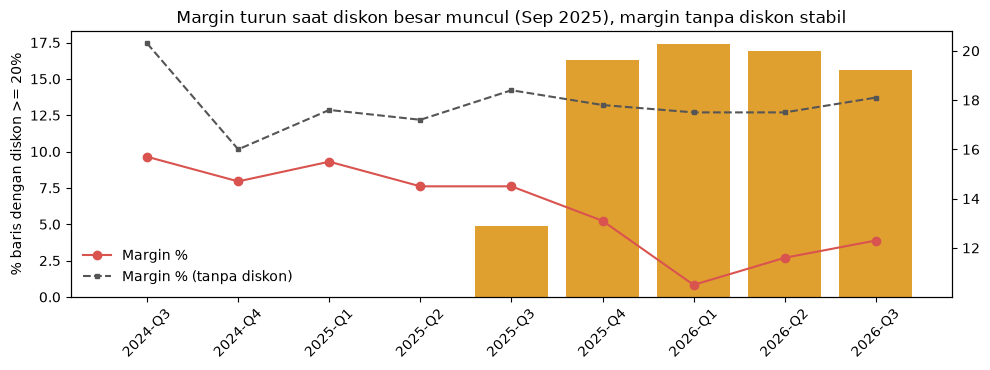

In [63]:
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(kuartal.index, kuartal['baris_diskon_20plus_pct'], color='#e0a030')
ax.set_ylabel('% baris dengan diskon >= 20%')
ax.tick_params(axis='x', rotation=45)

ax2 = ax.twinx()
ax2.plot(kuartal.index, kuartal['margin_pct'], color='#d9534f', marker='o', label='Margin %')
ax2.plot(kuartal.index, kuartal['margin_tanpa_diskon_pct'], color='#555', ls='--', marker='s', ms=3, label='Margin % (tanpa diskon)')
ax2.legend(loc='lower left', frameon=False)

plt.title('Margin turun saat diskon besar muncul (Sep 2025), margin tanpa diskon stabil')
plt.tight_layout()
plt.show()

In [64]:
# return & cancelled
selesai = df_final[df_final['status'] == 'Completed']['revenue'].sum()
ret_rev = -df_final[df_final['is_return']]['revenue'].sum()
can_rev = df_final[df_final['is_cancelled']]['revenue'].sum()

print(f"Return    : {df_final['is_return'].sum()} baris, Rp{ret_rev / 1e9:.2f} miliar = {ret_rev / selesai * 100:.1f}% dari revenue Completed")
print(f"Cancelled : {df_final['is_cancelled'].sum()} baris, Rp{can_rev / 1e9:.2f} miliar = {can_rev / (selesai + can_rev) * 100:.1f}% dari nilai order")

print('\nRata-rata net revenue per bulan kalender (Rp miliar):')
(m.assign(bulan=m.index.str[-2:]).groupby('bulan')['net_revenue'].mean() / 1e9).round(1)

Return    : 133 baris, Rp1.08 miliar = 1.9% dari revenue Completed
Cancelled : 210 baris, Rp1.73 miliar = 2.9% dari nilai order

Rata-rata net revenue per bulan kalender (Rp miliar):


bulan
01    1.7
02    2.1
03    3.1
04    2.1
05    2.1
06    2.1
07    2.8
08    2.4
09    2.2
10    1.9
11    2.6
12    3.0
Name: net_revenue, dtype: float64

**Insight utama** (periode 1 Sep 2024 - 15 Sep 2026):

- Total net revenue **Rp57,1 miliar**, gross profit **Rp7,6 miliar**, margin **13,4%**
- **Revenue naik tapi profit turun.** Perbandingan 12 bulan penuh: revenue **+13,4%** (26,2 -> 29,7 miliar), gross profit **-9,4%** (3,93 -> 3,55 miliar), margin 15,0% -> 12,0%
- **Penyebab: diskon besar sejak Sep 2025.** Sebelumnya tidak ada diskon 20/25/30% (0 baris), setelahnya ada 599 baris (sekitar 16-17% dari seluruh transaksi tiap kuartal)
  - baris tersebut menghasilkan Rp3,8 miliar dengan margin -10%, dan 46% dijual di bawah cost
  - 77% terjadi di channel Online, 58% ke customer Retail. Margin Online turun 13,9% -> 6,5%, Offline hanya 15,8% -> 14,7%
  - bukan karena cost naik: margin pada transaksi tanpa diskon stabil di sekitar 17-18% tiap kuartal
  - cost tidak ikut turun saat diskon, jadi batas aman diskon = 1 - rasio cost: Laptop sekitar 10-11%, Smartphone sekitar 13%, Printer sekitar 19%. Diskon 20-30% pada laptop pasti rugi
- **Mix produk lebih berpengaruh daripada region.** Laptop + Smartphone 64% revenue tapi 29% profit; Aksesoris + Peralatan Kantor + Networking 29% revenue tapi 64% profit. Margin region hanya berkisar 11,7% (Jawa Timur) - 15,1% (Sulawesi)
- **Tidak ada ketergantungan pada customer tertentu.** Top 10 hanya 6,5% revenue, semuanya Korporat. Korporat juga margin tertinggi (16,4%) vs UMKM 12,2% dan Retail 11,2%
- **Return 1,9% dan cancelled 2,9%**: relatif kecil, cukup dimonitor
- **Musiman**: puncak Maret, Juli, Desember; terendah Januari

### Rekomendasi

Untuk bisnis:
1. Batasi diskon per produk sesuai batas break-even (butuh approval di atasnya), mulai dari channel Online. Evaluasi apakah promo sejak Sep 2025 benar-benar menambah penjualan yang tidak akan terjadi di diskon lebih kecil
2. Dorong kategori margin tinggi (aksesoris, peralatan kantor, networking), misalnya bundling dengan laptop/smartphone, bukan menurunkan harga laptop/smartphone
3. Evaluasi performa pakai gross profit, bukan revenue saja. Revenue +13% menutupi profit yang turun 9%
4. Bulan Sep 2026 jangan dibandingkan sebelum bulan selesai

Untuk data:
1. Perbaiki export yang mengirim satuan ribuan sejak 1 Apr 2026 (sekitar 60% baris), dan tambahkan validasi harga terhadap katalog
2. Cegah duplikat saat load (order_id harus unik) dan jangan kirim test order ke export
3. Gunakan nilai baku untuk region, channel, category, satu format tanggal, dan diskon selalu dalam pecahan
4. Lengkapi COGS Networking dari sumbernya (sekitar 60% baris kosong)
5. Buat customer_id yang unik (id C saat ini dipakai ulang antar Retail/UMKM)
6. Tambahkan konfirmasi untuk order Retail dengan qty > 20

### Asumsi dan ketidakpastian

| Topik | Asumsi | Keyakinan |
|---|---|---|
| Satuan ribuan | *unit_price*, *revenue*, *cost* sama-sama dalam ribuan, dikali 1000 | Tinggi (rasio tepat 0.001 dan revenue cocok setelah fix) |
| Duplikat | Baris identik = double load | Tinggi |
| Cancelled | Order tidak terjadi, revenue = 0 | Tinggi |
| Return | Barang kembali ke stok, jadi cost ikut dibalik. Kalau barang dimusnahkan, profit overstated sekitar Rp0,9 miliar | Sedang |
| Cost Networking | Estimasi dari rasio cost produk. Dampak ke margin total sekitar 0,5 poin | Sedang |
| Outlier Retail (8 baris, Rp4,0 miliar) | Kemungkinan salah input, dipisah dari analisis utama. Kalau ikut dihitung, revenue +7% | Rendah-sedang |
| Region kosong | Tetap dipakai sebagai Unknown (131 baris, 1,5% revenue) | - |
| Ranking customer | Korporat bisa dipercaya, Retail/UMKM hanya indikatif | - |
| Format tanggal | DD/MM/YYYY untuk format dengan garis miring | Tinggi |
| Periode | Data berakhir 15 Sep 2026 | Tinggi |

In [65]:
from pathlib import Path

OUT = Path('output'); OUT.mkdir(exist_ok=True)

kolom = ['order_id', 'order_date', 'year', 'quarter', 'month', 'year_month', 'year_quarter', 'region', 'channel', 'customer_id',
         'customer_type', 'sales_rep', 'category', 'product', 'qty', 'discount', 'discount_band', 'status', 'unit_price', 'revenue', 'cost',
         'net_revenue', 'net_cost', 'gross_profit', 'list_value', 'cost_imputed', 'price_scale_fixed', 'discount_was_pct', 'qty_outlier']

df_clean[kolom].to_csv(OUT / 'df_clean.csv', index=False)

with pd.ExcelWriter(OUT / 'soal1_summary.xlsx') as xw:
    monthly.reset_index().to_excel(xw, sheet_name='monthly', index=False)
    reg_cat.reset_index().to_excel(xw, sheet_name='region_x_category', index=False)
    rev_pivot.to_excel(xw, sheet_name='revenue_pivot')
    margin_pivot.to_excel(xw, sheet_name='margin_pivot')
    top10.reset_index().to_excel(xw, sheet_name='top10_customer', index=False)
    hasil.reset_index().to_excel(xw, sheet_name='sensitivitas', index=False)

sorted(p.name for p in OUT.iterdir())

['df_clean.csv', 'soal1_summary.xlsx']